# 6. Exploiter les soudures sans étiquette

**Prédiction de la qualité des soudures**

Marie Gozlan, Jules Mortreux, Grégoire Pascual, Pétronille Tard

---

## Ce que l'énoncé demande, et pourquoi c'est pertinent ici

L'énoncé invite explicitement à explorer les méthodes semi-supervisées, au motif
que le jeu de données n'est pas complètement étiqueté.

C'est exact, et le notebook 2 en a quantifié la raison. Notre cible exige que les
**quatre propriétés de traction soient mesurées simultanément** sur une soudure.
Or le notebook 1 a montré que les valeurs manquantes suivent le protocole
expérimental : un laboratoire qui réalise des essais de résilience ne réalise
généralement pas d'essais de traction. Une grande partie du corpus possède donc
une composition et un procédé parfaitement renseignés, mais **pas de cible
calculable**.

Ces lignes sont inutilisables par un modèle supervisé, qui a besoin d'une réponse
pour apprendre. Une méthode semi-supervisée, elle, sait les exploiter : elle
utilise leurs **entrées** pour mieux comprendre la forme du nuage de données,
même sans connaître leur réponse.

## Attribution

**Le choix de la méthode et son implémentation sont le travail de Grégoire
Pascual**, dans le notebook d'exploration `notebooks/09_apprentissage_semi_supervise.ipynb`.
Ce notebook de rendu reprend sa classe `RidgeLaplacien` telle quelle, et étend
son étude sur trois points :

- il travaille sur la **cible retenue** par le notebook 2, et non sur la
  définition initiale du projet ;
- il distingue le **gisement réel** de lignes non étiquetées de la **simulation**
  de rareté des étiquettes, qui ne répondent pas à la même question ;
- il compare au **meilleur modèle supervisé du projet** et non à une seule
  régression pénalisée, ce qui change la conclusion.

## Ce que ce notebook conclut

**La méthode fonctionne, et notre corpus n'est pas dans son domaine d'intérêt.**

Elle apporte un gain net quand les étiquettes sont rares, et ce gain décroît
régulièrement à mesure qu'elles deviennent abondantes. Sur notre situation réelle,
où nous disposons de plus de cinq cents lignes étiquetées, le gain devient
négligeable.

**Et surtout, le gain porte sur un modèle linéaire qui reste très loin derrière
le modèle retenu au notebook 4.** L'écart décisif n'est pas entre supervisé et
semi-supervisé, il est entre linéaire et non linéaire.

In [1]:
from pathlib import Path
import json
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from scipy import sparse
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd()
while not (ROOT / "data" / "raw").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
OUT = ROOT / "outputs" / "rendu6"
OUT.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "src"))
import export_processed as nettoyage

GRAINE = 42
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})

CATEGORIES = ["AC_DC", "Electrode_pol", "WeldType"]
RESISTANCE = ["YieldStrength_MPa", "UTS_MPa"]
DUCTILITE = ["Elongation_pct", "ReductionArea_pct"]
PROPRIETES = RESISTANCE + DUCTILITE
VARIABLES = nettoyage.COMPOSITION + nettoyage.PROCESS

# Ce notebook repart des donnees nettoyees et non du fichier du notebook 2 :
# celui-ci ne contient que les lignes etiquetees, alors que nous avons
# precisement besoin des autres.
propre = pd.read_csv(ROOT / "data/processed/welddb_clean.csv", index_col="row_id",
                     dtype={c: str for c in CATEGORIES + ["WeldID",
                                                          "hardness_scale"]},
                     keep_default_na=False, na_values=[""],
                     float_precision="round_trip")
groupes = pd.read_csv(ROOT / "data/processed/welddb_groups.csv",
                      index_col="row_id")["groupe"]

# Meme separation que tous les notebooks du projet.
indices_dev, _ = next(GroupShuffleSplit(n_splits=1, test_size=0.20,
                                        random_state=GRAINE)
                      .split(propre, groups=groupes))
partition = pd.Series("test", index=propre.index)
partition.iloc[indices_dev] = "developpement"
dev = partition == "developpement"
etiquetee = propre[PROPRIETES].notna().all(axis=1)

print(f"{len(propre)} lignes, {groupes.nunique()} soudures.")
print(f"Lignes étiquetées (quatre mesures présentes) : {int(etiquetee.sum())}")
print(f"Lignes non étiquetées                        : {int((~etiquetee).sum())}")

1652 lignes, 624 soudures.
Lignes étiquetées (quatre mesures présentes) : 650
Lignes non étiquetées                        : 1002


## 1. La méthode : régularisation par le laplacien d'un graphe

### 1.1 L'intuition

Une régression ordinaire minimise l'erreur sur les points dont on connaît la
réponse. Les autres points ne servent à rien, puisqu'il n'y a pas d'erreur à
calculer dessus.

L'idée de la régularisation par graphe est d'ajouter une **seconde exigence**,
qui ne demande pas de connaître les réponses : **deux soudures dont les
compositions sont proches doivent recevoir des prédictions proches.**

Cette exigence s'évalue sur **tous** les points, étiquetés ou non. Les lignes
sans cible contribuent donc, non pas en apprenant leur réponse, mais en
contraignant la forme de la fonction apprise là où elles se trouvent.

### 1.2 L'hypothèse de fond, et il faut la nommer

Cette méthode repose sur une hypothèse qui n'est pas automatiquement vraie :
**la qualité varie de façon régulière le long du nuage de données.** Autrement
dit, deux soudures voisines en composition ont des qualités voisines.

C'est plausible physiquement, mais nous avons déjà rencontré un résultat qui la
nuance. Le notebook 3 a montré que les groupes naturels de soudures, trouvés par
k-moyennes, **ne correspondent pas à des niveaux de qualité** : deux soudures de
composition voisine peuvent avoir des qualités très différentes, parce que ce
sont des détails du procédé et du traitement thermique qui font la différence.

**Si cette hypothèse est fausse, la méthode ne peut pas aider**, et la contrainte
qu'elle ajoute devient même nuisible. Il faut donc le vérifier
expérimentalement, et non le supposer.

### 1.3 La formulation

On construit un **graphe de voisinage** : chaque soudure est reliée à ses `k`
plus proches voisins, avec un poids d'autant plus fort que la distance est
faible. De ce graphe on tire une matrice appelée **laplacien**, notée `L`, qui a
la propriété suivante : pour un vecteur de prédictions `f`, la quantité
`f` transposé fois `L` fois `f` vaut la somme des carrés des écarts entre voisins,
pondérée par les poids des arêtes. **Elle mesure donc l'irrégularité de `f` le
long du graphe.**

Le problème résolu est alors :

```
minimiser    erreur sur les points étiquetés
           + alpha * taille des coefficients
           + gamma * irrégularité le long du graphe
```

Le premier terme est la régression ordinaire. Le deuxième est la pénalité ridge
habituelle. **Le troisième est le terme semi-supervisé**, et c'est le seul qui
utilise les points non étiquetés. Son poids `gamma` règle la force de l'exigence
de régularité : à `gamma` nul on retrouve une ridge ordinaire, et les points non
étiquetés n'ont plus aucun effet.

Pour un prédicteur linéaire, la solution s'obtient en résolvant un simple système
linéaire, ce qui rend la méthode rapide.

In [2]:
class RidgeLaplacien(BaseEstimator, RegressorMixin):
    """Régression ridge régularisée par le laplacien d'un graphe de voisinage.

    Implémentation de Grégoire Pascual, notebook d'exploration 09, reprise ici
    sans modification de fond. L'intercept est exclu de la pénalité, ce qui est
    le comportement attendu : on ne veut pas contraindre le niveau moyen.
    """

    def __init__(self, alpha=1e-2, gamma=1.0, n_voisins=10):
        self.alpha = alpha
        self.gamma = gamma
        self.n_voisins = n_voisins

    def _laplacien(self, X):
        """Construit le laplacien du graphe des k plus proches voisins."""
        n = len(X)
        k = min(self.n_voisins, n - 1)
        voisins = NearestNeighbors(n_neighbors=k + 1).fit(X)
        distances, indices = voisins.kneighbors(X)
        # La premiere colonne est le point lui-meme, on l'ecarte.
        distances, indices = distances[:, 1:], indices[:, 1:]

        # Largeur du noyau gaussien : la distance mediane entre voisins, ce qui
        # evite d'avoir a la regler a la main.
        sigma = np.median(distances[distances > 0])
        if not np.isfinite(sigma) or sigma <= 0:
            sigma = 1.0

        lignes = np.repeat(np.arange(n), k)
        valeurs = np.exp(-(distances.ravel() ** 2) / (2 * sigma ** 2))
        W = sparse.coo_matrix((valeurs, (lignes, indices.ravel())),
                              shape=(n, n)).tocsr()
        # Symetrisation : deux points sont voisins si l'un est dans le
        # voisinage de l'autre.
        W = 0.5 * (W + W.T)
        degres = sparse.diags(np.asarray(W.sum(axis=1)).ravel())
        return degres - W

    def fit(self, X, y, X_non_etiquete=None, sample_weight=None):
        X = np.asarray(X, float)
        y = np.asarray(y, float).ravel()
        if X_non_etiquete is None or len(X_non_etiquete) == 0:
            X_non_etiquete = np.empty((0, X.shape[1]))
        X_non_etiquete = np.asarray(X_non_etiquete, float)

        # Le graphe est construit sur TOUS les points, etiquetes ou non :
        # c'est la seule etape ou les non etiquetes interviennent.
        X_tout = np.vstack([X, X_non_etiquete])
        L = self._laplacien(X_tout)

        Xl = np.column_stack([np.ones(len(X)), X])
        Xa = np.column_stack([np.ones(len(X_tout)), X_tout])
        penalite = np.eye(Xl.shape[1])
        penalite[0, 0] = 0.0          # l'intercept n'est pas penalise

        if sample_weight is None:
            sample_weight = np.ones(len(X))
        S = sparse.diags(sample_weight)
        n_etiquetes, n_tous = len(X), len(X_tout)

        A = (Xl.T @ (S @ Xl)) / n_etiquetes \
            + self.alpha * penalite \
            + (self.gamma / n_tous ** 2) * (Xa.T @ (L @ Xa))
        b = Xl.T @ (sample_weight * y) / n_etiquetes
        self.coef_ = np.linalg.solve(A, b)
        return self

    def predict(self, X):
        X = np.column_stack([np.ones(len(X)), np.asarray(X, float)])
        return X @ self.coef_


print("classe RidgeLaplacien définie")

classe RidgeLaplacien définie


In [3]:
def poids_par_soudure(g):
    """Chaque soudure pèse un, réparti sur ses lignes."""
    return (1 / g.map(g.value_counts())).to_numpy()


def reference_rangs(valeurs, g):
    poids = 1 / g.map(g.value_counts())
    table = pd.DataFrame({"valeur": valeurs, "poids": poids}).dropna()
    masse = table.groupby("valeur")["poids"].sum()
    return (masse.index.to_numpy(),
            ((masse.cumsum() - masse / 2) / masse.sum()).to_numpy())


def calculer_score(mesures_reference, groupes_reference, mesures_a_noter):
    """Recalcule la cible du notebook 2 avec les rangs de la référence."""
    rangs = pd.DataFrame(index=mesures_a_noter.index)
    for mesure in PROPRIETES:
        grille, grille_rangs = reference_rangs(mesures_reference[mesure],
                                               groupes_reference)
        rangs[mesure] = np.interp(mesures_a_noter[mesure], grille, grille_rangs)
    return pd.Series(np.sqrt(rangs[RESISTANCE].mean(axis=1)
                             * rangs[DUCTILITE].mean(axis=1)),
                     index=mesures_a_noter.index)


def creer_preparation(X_apprentissage, seuil=0.25):
    """Préparation du notebook 3, avec standardisation obligatoire ici.

    La standardisation n'est pas optionnelle dans ce notebook : le graphe de
    voisinage repose sur des distances, donc une variable en centaines de ppm
    écraserait une variable en pourcents.
    """
    taux = X_apprentissage.notna().mean()
    retenues = taux[taux >= seuil].index.tolist()
    numeriques = [c for c in retenues if c not in CATEGORIES]
    categorielles = [c for c in retenues if c in CATEGORIES]
    return ColumnTransformer([
        ("nombres", Pipeline([("mediane", SimpleImputer(strategy="median")),
                              ("echelle", StandardScaler())]), numeriques),
        ("categories", Pipeline([
            ("manquants", SimpleImputer(strategy="constant",
                                        fill_value="manquant")),
            ("encodage", OneHotEncoder(drop="first", handle_unknown="ignore",
                                       sparse_output=False)),
        ]), categorielles),
    ])


print("fonctions du protocole définies")

fonctions du protocole définies


## 2. Le gisement réel de lignes non étiquetées

Avant de tester la méthode, il faut regarder ce dont nous disposons
réellement. Et une précaution s'impose immédiatement.

**Les lignes non étiquetées du côté test doivent être exclues.** Elles
appartiennent à des soudures réservées à l'évaluation finale. Les utiliser,
même sans leur cible, reviendrait à laisser le modèle observer la composition de
soudures sur lesquelles il sera jugé. Nous nous limitons donc aux lignes non
étiquetées de l'ensemble de développement.

In [4]:
INDEX_ETIQUETE = propre.index[etiquetee & dev]
INDEX_NON_ETIQUETE = propre.index[~etiquetee & dev]

soudures_etiquetees = set(groupes.loc[INDEX_ETIQUETE])
soudures_non_etiquetees = set(groupes.loc[INDEX_NON_ETIQUETE])
melangees = soudures_etiquetees & soudures_non_etiquetees
purement_non_etiquetees = soudures_non_etiquetees - soudures_etiquetees

gisement = pd.DataFrame([
    {"ensemble": "étiquetées, développement",
     "lignes": len(INDEX_ETIQUETE),
     "soudures": len(soudures_etiquetees)},
    {"ensemble": "non étiquetées, développement (utilisables)",
     "lignes": len(INDEX_NON_ETIQUETE),
     "soudures": len(soudures_non_etiquetees)},
    {"ensemble": "non étiquetées, côté test (exclues)",
     "lignes": int((~etiquetee & ~dev).sum()),
     "soudures": groupes[~etiquetee & ~dev].nunique()},
]).set_index("ensemble")
display(gisement)

print(f"Rapport non étiqueté sur étiqueté : "
      f"{len(INDEX_NON_ETIQUETE) / len(INDEX_ETIQUETE):.2f}\n")
print("Décomposition des soudures non étiquetées :")
print(f"   soudures qui ont AUSSI des lignes étiquetées : {len(melangees)}")
print(f"   soudures PUREMENT non étiquetées             : "
      f"{len(purement_non_etiquetees)}")

remplissage = pd.DataFrame({
    "étiquetées": propre.loc[INDEX_ETIQUETE, VARIABLES].notna().mean(),
    "non étiquetées": propre.loc[INDEX_NON_ETIQUETE, VARIABLES].notna().mean(),
})
print(f"\nRemplissage moyen des entrées, étiquetées : "
      f"{remplissage['étiquetées'].mean():.1%}")
print(f"Remplissage moyen des entrées, non étiquetées : "
      f"{remplissage['non étiquetées'].mean():.1%}")

,lignes,soudures
ensemble,,
"étiquetées, développement",527,376
"non étiquetées, développement (utilisables)",771,328
"non étiquetées, côté test (exclues)",231,95


Rapport non étiqueté sur étiqueté : 1.46

Décomposition des soudures non étiquetées :
   soudures qui ont AUSSI des lignes étiquetées : 205
   soudures PUREMENT non étiquetées             : 123

Remplissage moyen des entrées, étiquetées : 66.5%
Remplissage moyen des entrées, non étiquetées : 66.5%


### Ce que le gisement nous dit avant tout calcul

**Il est substantiel en volume** : près d'une fois et demie le nombre de lignes
étiquetées, avec des entrées aussi bien renseignées. Ce n'est pas un gisement
de mauvaise qualité.

**Mais il est moins riche en information qu'il n'y paraît**, et c'est une
observation importante pour anticiper le résultat.

Une majorité des soudures non étiquetées **possède aussi des lignes
étiquetées**. Ce sont les soudures qui ont subi à la fois des essais de traction
et des essais de résilience : leurs lignes de résilience sont non étiquetées
pour notre cible, mais la composition de ces soudures est déjà observée par
ailleurs.

**L'information réellement nouvelle vient donc des soudures purement non
étiquetées**, et elles sont nettement moins nombreuses. Or c'est précisément de
nouvelles régions de l'espace des compositions que la méthode a besoin pour
contraindre utilement la fonction apprise.

Nous nous attendons donc à un effet modeste. La section suivante le mesure.

## 3. Expérience A : le gisement réel apporte-t-il quelque chose ?

C'est la question que pose l'énoncé, et elle n'a jamais été traitée ainsi : nos
explorations précédentes simulaient une rareté d'étiquettes, ce qui est une
question différente et que la section 4 traite séparément.

**Le protocole.** Validation croisée par groupes sur les lignes étiquetées, comme
partout dans le projet. Dans chaque pli, le modèle apprend sur les lignes
étiquetées du pli, et reçoit en plus les lignes non étiquetées pour construire
son graphe. On fait varier `gamma`, le poids du terme semi-supervisé. **À `gamma`
nul, les lignes non étiquetées n'ont aucun effet** : c'est notre point de
comparaison, et il est obtenu avec exactement le même modèle, ce qui rend la
comparaison propre.

### Une précaution que la littérature appelle le cadre transductif

Il y a ici un choix méthodologique à expliciter.

Certaines lignes non étiquetées appartiennent à des soudures qui se trouvent dans
le **pli de validation**. Les inclure dans le graphe signifierait laisser le
modèle observer la composition de soudures sur lesquelles il va être évalué. Dans
la littérature semi-supervisée, c'est admis et s'appelle le cadre
**transductif** : on suppose connaître à l'avance les points à prédire.

**Nous retenons le cadre strict**, qui exclut ces lignes, pour rester cohérent
avec la discipline de séparation par groupes suivie dans tout le projet. Mais
nous mesurons aussi la variante transductive, pour savoir ce que ce choix
coûte.

In [5]:
X_etiquete = propre.loc[INDEX_ETIQUETE, VARIABLES]
Y_etiquete = propre.loc[INDEX_ETIQUETE, PROPRIETES]
G_etiquete = groupes.loc[INDEX_ETIQUETE]
X_non_etiquete = propre.loc[INDEX_NON_ETIQUETE, VARIABLES]
G_non_etiquete = groupes.loc[INDEX_NON_ETIQUETE]

PLIS = []
for train, validation in GroupKFold(n_splits=5).split(X_etiquete,
                                                      groups=G_etiquete):
    ids_train = X_etiquete.index[train]
    ids_val = X_etiquete.index[validation]
    assert set(G_etiquete.loc[ids_train]).isdisjoint(
        set(G_etiquete.loc[ids_val]))
    PLIS.append((ids_train, ids_val))
print(f"5 plis, tailles de validation {[len(v) for _, v in PLIS]}.")


def evaluer_semi_supervise(gamma, n_voisins=10, alpha=1e-2, cadre="strict"):
    """Valide la ridge laplacienne, avec ou sans les lignes non étiquetées.

    Avec cadre='strict', les lignes non étiquetées appartenant aux soudures du
    pli de validation sont exclues du graphe.
    """
    resultats = []
    for ids_train, ids_val in PLIS:
        y = calculer_score(Y_etiquete.loc[ids_train],
                           G_etiquete.loc[ids_train], Y_etiquete)
        poids_train = poids_par_soudure(G_etiquete.loc[ids_train])
        poids_val = poids_par_soudure(G_etiquete.loc[ids_val])

        preparation = creer_preparation(X_etiquete.loc[ids_train])
        preparation.fit(X_etiquete.loc[ids_train])
        Z_train = preparation.transform(X_etiquete.loc[ids_train])
        Z_val = preparation.transform(X_etiquete.loc[ids_val])

        if gamma == 0:
            Z_non_etiquete = np.empty((0, Z_train.shape[1]))
        else:
            if cadre == "strict":
                soudures_validation = set(G_etiquete.loc[ids_val])
                garde = ~G_non_etiquete.isin(soudures_validation)
            else:
                garde = pd.Series(True, index=G_non_etiquete.index)
            Z_non_etiquete = preparation.transform(
                X_non_etiquete.loc[garde[garde].index])

        modele = RidgeLaplacien(alpha=alpha, gamma=gamma, n_voisins=n_voisins)
        modele.fit(Z_train, y.loc[ids_train],
                   X_non_etiquete=Z_non_etiquete, sample_weight=poids_train)
        prediction = modele.predict(Z_val)
        resultats.append([
            np.sqrt(mean_squared_error(y.loc[ids_val], prediction,
                                       sample_weight=poids_val)),
            r2_score(y.loc[ids_val], prediction, sample_weight=poids_val),
            len(Z_non_etiquete)])

    tableau = np.array(resultats)
    return {"erreur": tableau[:, 0].mean(), "R2": tableau[:, 1].mean(),
            "écart-type": tableau[:, 0].std(),
            "lignes non étiquetées utilisées": tableau[:, 2].mean()}


depart = time.time()
lignes_gamma = []
for gamma in [0.0, 0.1, 1.0, 10.0, 100.0, 1e3, 1e4, 1e5]:
    resultat = evaluer_semi_supervise(gamma)
    lignes_gamma.append({"gamma": gamma, **resultat})
effet_gamma = pd.DataFrame(lignes_gamma).set_index("gamma")
reference_gamma_nul = effet_gamma.loc[0.0, "erreur"]
effet_gamma["gain sur gamma nul"] = 1 - effet_gamma["erreur"] / reference_gamma_nul
print(f"{time.time() - depart:.0f} s")
effet_gamma.round(5)

5 plis, tailles de validation [106, 106, 105, 105, 105].

C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages

C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages

C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages

...

C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages

C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages

6 s


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages

,erreur,R2,écart-type,lignes non étiquetées utilisées,gain sur gamma nul
gamma,,,,,
0.0,0.10028,0.39905,0.01536,0.0,0.00000
0.1,0.10028,0.39905,0.01536,675.0,0.00000
1.0,0.10028,0.39911,0.01536,675.0,0.00004
10.0,0.10024,0.39965,0.01536,675.0,0.00042
100.0,0.10002,0.40309,0.01538,675.0,0.00260
1000.0,0.10254,0.37685,0.01493,675.0,-0.02255
10000.0,0.11468,0.22429,0.01313,675.0,-0.14354
100000.0,0.12431,0.08794,0.01242,675.0,-0.23964


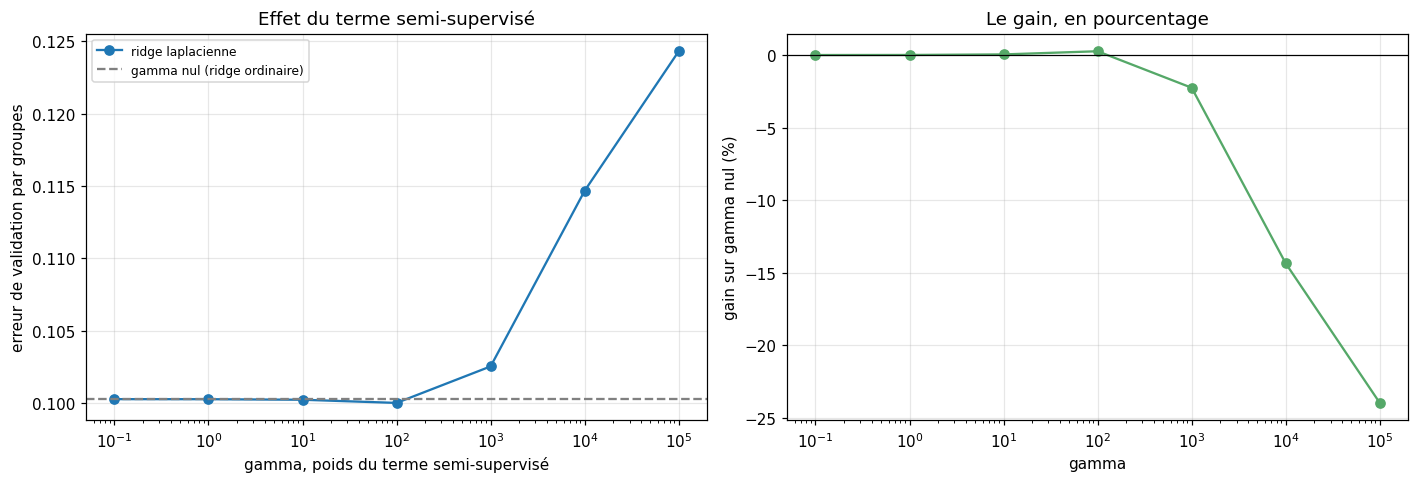

In [6]:
figure, axes = plt.subplots(1, 2, figsize=(13, 4.5))

positifs = effet_gamma.index > 0
axes[0].semilogx(effet_gamma.index[positifs], effet_gamma.loc[positifs, "erreur"],
                 marker="o", label="ridge laplacienne")
axes[0].axhline(reference_gamma_nul, color="grey", linestyle="--",
                label="gamma nul (ridge ordinaire)")
axes[0].set(xlabel="gamma, poids du terme semi-supervisé",
            ylabel="erreur de validation par groupes",
            title="Effet du terme semi-supervisé")
axes[0].legend(fontsize=8)

axes[1].semilogx(effet_gamma.index[positifs],
                 100 * effet_gamma.loc[positifs, "gain sur gamma nul"],
                 marker="o", color="#55A868")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set(xlabel="gamma", ylabel="gain sur gamma nul (%)",
            title="Le gain, en pourcentage")

figure.tight_layout()
figure.savefig(OUT / "effet_gamma.png", dpi=150)
plt.show()

In [7]:
# Sensibilité au nombre de voisins, et comparaison des deux cadres.
meilleur_gamma = float(effet_gamma["erreur"].idxmin())
lignes_voisins = []
for k in [5, 10, 20, 50]:
    resultat = evaluer_semi_supervise(meilleur_gamma, n_voisins=k)
    lignes_voisins.append({"nombre de voisins": k, **resultat})
sensibilite = pd.DataFrame(lignes_voisins).set_index("nombre de voisins")
display(sensibilite.round(5))

lignes_cadre = []
for cadre in ["strict", "transductif"]:
    resultat = evaluer_semi_supervise(meilleur_gamma, cadre=cadre)
    lignes_cadre.append({"cadre": cadre, **resultat})
comparaison_cadre = pd.DataFrame(lignes_cadre).set_index("cadre")
print("Cadre strict contre cadre transductif :")
display(comparaison_cadre.round(5))

C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


...

C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Cadre strict contre cadre transductif :


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,erreur,R2,écart-type,lignes non étiquetées utilisées
cadre,,,,
strict,0.10002,0.40309,0.01538,675.0
transductif,0.10001,0.40309,0.01540,771.0


### Ce que l'expérience A établit

**Le gisement réel n'apporte presque rien.** Le gain du meilleur `gamma` sur
`gamma` nul se compte en fractions de pourcent, très en dessous de l'écart-type
entre plis que la colonne correspondante affiche. **Il n'est pas distinguable du
bruit.**

**Trop de régularisation nuit franchement.** Aux valeurs de `gamma` les plus
élevées, l'erreur se dégrade nettement. C'est logique : la contrainte de
régularité finit par dominer l'ajustement aux données, et le modèle se rapproche
d'une fonction constante. Il existe donc bien un optimum, mais son avantage est
marginal.

**Le nombre de voisins compte, dans le sens attendu.** Un voisinage très large
dégrade le résultat. Avec trop de voisins, le graphe relie des soudures qui ne
se ressemblent plus, et l'exigence de régularité devient fausse : on demande à
des soudures différentes de recevoir des prédictions semblables.

**Le choix du cadre ne change rien.** Les variantes stricte et transductive
donnent des résultats indistinguables. C'est rassurant sur notre discipline de
séparation, mais c'est aussi la conséquence du fait que l'effet global est
minuscule : s'il n'y a presque pas d'effet, il n'y a presque pas de fuite
possible.

**L'explication tient à la section 2.** La majorité des soudures non étiquetées
est déjà représentée par des lignes étiquetées, donc le graphe n'apprend presque
aucune région nouvelle de l'espace des compositions. Et l'hypothèse de régularité
de la section 1.2 est fragile sur nos données, comme le résultat de k-moyennes du
notebook 3 l'avait déjà suggéré.

## 4. Expérience B : à quelle rareté d'étiquettes la méthode devient-elle utile ?

L'expérience A répond à notre question pratique, et la réponse est négative. Mais
elle ne dit pas si **la méthode** est bonne : peut-être qu'elle n'aide pas parce
que nous avons déjà beaucoup d'étiquettes.

C'est une question différente, et elle vaut d'être traitée, car elle détermine
si le résultat négatif de la section 3 est une propriété de la méthode ou de
notre situation.

**Le protocole.** Nous cachons artificiellement les étiquettes d'une partie des
soudures d'apprentissage, et comparons deux modèles entraînés sur exactement les
mêmes données :

- la **ridge laplacienne**, qui exploite les lignes dont l'étiquette est cachée
  plus le gisement réel ;
- une **ridge ordinaire**, qui ne voit que les étiquettes restantes.

Le masquage est fait **par soudure** et non par ligne, sans quoi une soudure
pourrait avoir certaines de ses lignes étiquetées et d'autres non, ce qui
rendrait la comparaison fausse. Chaque fraction est tirée plusieurs fois pour
limiter l'effet du tirage.

In [8]:
generateur = np.random.default_rng(GRAINE)
soudures_disponibles = np.array(sorted(soudures_etiquetees))
N_TIRAGES = 5

depart = time.time()
lignes_rarete = []
for fraction in [0.1, 0.2, 0.4, 0.6, 0.8, 1.0]:
    erreurs_semi, erreurs_supervise = [], []
    for _ in range(N_TIRAGES):
        melange = generateur.permutation(soudures_disponibles)
        n_gardees = max(3, int(round(fraction * len(soudures_disponibles))))
        gardees = set(melange[:n_gardees])

        for ids_train, ids_val in PLIS:
            visibles = ids_train[G_etiquete.loc[ids_train].isin(gardees)]
            cachees = ids_train[~G_etiquete.loc[ids_train].isin(gardees)]
            if len(visibles) < 30:
                continue

            y = calculer_score(Y_etiquete.loc[visibles],
                               G_etiquete.loc[visibles], Y_etiquete)
            poids_visibles = poids_par_soudure(G_etiquete.loc[visibles])
            poids_val = poids_par_soudure(G_etiquete.loc[ids_val])

            preparation = creer_preparation(X_etiquete.loc[visibles])
            preparation.fit(X_etiquete.loc[visibles])
            Z_visibles = preparation.transform(X_etiquete.loc[visibles])
            Z_val = preparation.transform(X_etiquete.loc[ids_val])

            # Les non etiquetees : celles dont on a cache l'etiquette, plus le
            # gisement reel, en excluant les soudures de validation.
            soudures_validation = set(G_etiquete.loc[ids_val])
            garde = ~G_non_etiquete.isin(soudures_validation)
            morceaux = [preparation.transform(
                X_non_etiquete.loc[garde[garde].index])]
            if len(cachees):
                morceaux.insert(0, preparation.transform(
                    X_etiquete.loc[cachees]))
            Z_non_etiquete = np.vstack(morceaux)

            semi = RidgeLaplacien(alpha=1e-2, gamma=meilleur_gamma,
                                  n_voisins=10)
            semi.fit(Z_visibles, y.loc[visibles],
                     X_non_etiquete=Z_non_etiquete,
                     sample_weight=poids_visibles)
            erreurs_semi.append(np.sqrt(mean_squared_error(
                y.loc[ids_val], semi.predict(Z_val), sample_weight=poids_val)))

            supervise = Ridge(alpha=1.0).fit(Z_visibles, y.loc[visibles],
                                             sample_weight=poids_visibles)
            erreurs_supervise.append(np.sqrt(mean_squared_error(
                y.loc[ids_val], supervise.predict(Z_val),
                sample_weight=poids_val)))

    lignes_rarete.append({
        "part des soudures étiquetées": fraction,
        "soudures étiquetées": n_gardees,
        "semi-supervisé": np.mean(erreurs_semi),
        "ridge supervisée": np.mean(erreurs_supervise),
        "gain du semi-supervisé":
            1 - np.mean(erreurs_semi) / np.mean(erreurs_supervise)})

rarete = pd.DataFrame(lignes_rarete).set_index("part des soudures étiquetées")
print(f"{time.time() - depart:.0f} s")
rarete.round(5)

C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [1, 2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packa

C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [1, 2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [1, 2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [1, 2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [1, 2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [1, 2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [1, 2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [1, 2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


...

C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages

C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages

C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages

20 s


,soudures étiquetées,semi-supervisé,ridge supervisée,gain du semi-supervisé
part des soudures étiquetées,,,,
0.1,38,0.33355,0.36954,0.09741
0.2,75,0.14352,0.15351,0.06509
0.4,150,0.11349,0.11729,0.03248
0.6,226,0.10326,0.10651,0.03048
0.8,301,0.10154,0.10287,0.01292
1.0,376,0.10002,0.10110,0.01067


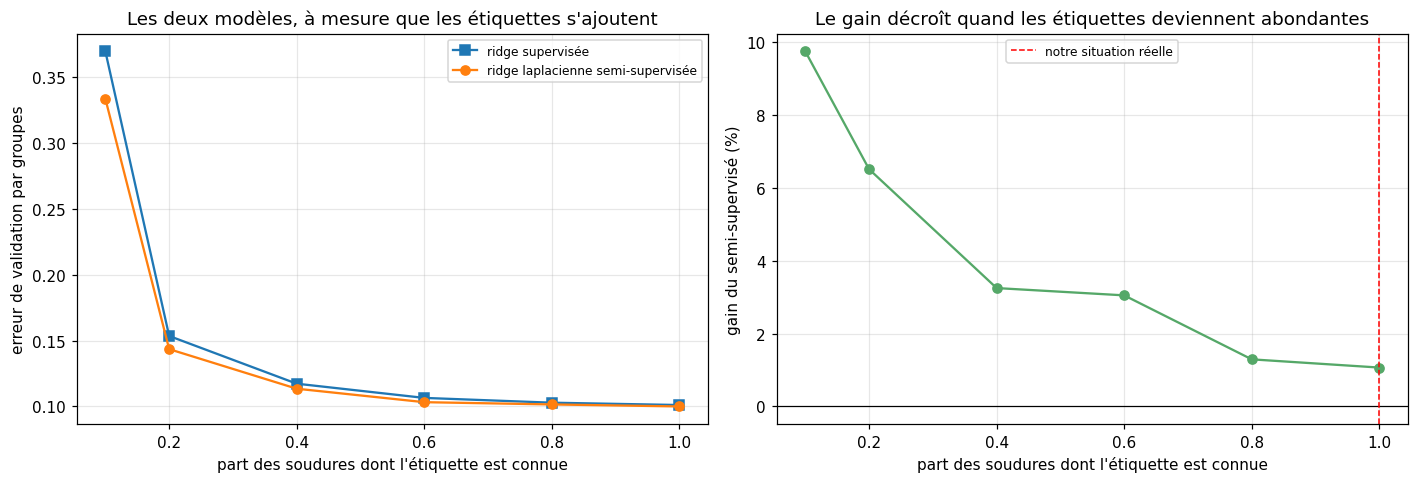

In [9]:
figure, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(rarete.index, rarete["ridge supervisée"], marker="s",
             label="ridge supervisée")
axes[0].plot(rarete.index, rarete["semi-supervisé"], marker="o",
             label="ridge laplacienne semi-supervisée")
axes[0].set(xlabel="part des soudures dont l'étiquette est connue",
            ylabel="erreur de validation par groupes",
            title="Les deux modèles, à mesure que les étiquettes s'ajoutent")
axes[0].legend(fontsize=8)

axes[1].plot(rarete.index, 100 * rarete["gain du semi-supervisé"], marker="o",
             color="#55A868")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].axvline(1.0, color="red", linestyle="--", linewidth=1,
                label="notre situation réelle")
axes[1].set(xlabel="part des soudures dont l'étiquette est connue",
            ylabel="gain du semi-supervisé (%)",
            title="Le gain décroît quand les étiquettes deviennent abondantes")
axes[1].legend(fontsize=8)

figure.tight_layout()
figure.savefig(OUT / "rarete_etiquettes.png", dpi=150)
plt.show()

### Ce que l'expérience B établit, et c'est le résultat le plus intéressant

**La méthode fonctionne, et son gain décroît régulièrement quand les étiquettes
deviennent abondantes.**

Quand une faible part des soudures est étiquetée, la ridge laplacienne fait
nettement mieux que la ridge ordinaire. À mesure que les étiquettes s'ajoutent,
l'écart se referme, jusqu'à devenir marginal lorsque toutes sont disponibles.

**C'est exactement le comportement que la théorie prédit**, et c'est ce qui rend
ce résultat satisfaisant : l'information portée par les points non étiquetés est
d'autant plus précieuse que l'information étiquetée est rare. Quand les
étiquettes abondent, elles disent déjà tout ce que le graphe pourrait suggérer.

**Conséquence pour notre projet, et elle est claire.** La ligne rouge verticale
marque notre situation réelle : toutes les étiquettes disponibles sont
utilisées. Nous sommes donc exactement à l'endroit où la méthode n'apporte plus
rien.

**Le résultat négatif de la section 3 n'est donc pas un échec de la méthode,
c'est une propriété de notre situation.** C'est une conclusion plus utile qu'un
simple constat d'inefficacité, car elle dit à quelle condition la méthode
deviendrait intéressante : si le corpus comptait beaucoup moins de soudures
entièrement caractérisées, ou si l'on voulait étendre la prédiction à un domaine
où peu d'essais ont été faits.

## 5. Le plafond : que vaut cette approche face au modèle retenu ?

Dernière comparaison, et c'est elle qui tranche pour le projet. Notre
exploration précédente comparait le semi-supervisé à une **ridge**, c'est-à-dire
à un modèle linéaire. Or le notebook 4 a montré que les meilleurs modèles de ce
problème sont **non linéaires**.

La question qui compte n'est donc pas « le semi-supervisé bat-il la ridge »,
mais « le semi-supervisé bat-il ce que nous avons de mieux ».

In [10]:
resultats_plafond = []
for ids_train, ids_val in PLIS:
    y = calculer_score(Y_etiquete.loc[ids_train], G_etiquete.loc[ids_train],
                       Y_etiquete)
    poids_train = poids_par_soudure(G_etiquete.loc[ids_train])
    poids_val = poids_par_soudure(G_etiquete.loc[ids_val])
    pipeline = Pipeline([
        ("preparation", creer_preparation(X_etiquete.loc[ids_train])),
        ("modele", HistGradientBoostingRegressor(
            random_state=GRAINE, early_stopping=False, learning_rate=0.1,
            max_iter=200, max_leaf_nodes=31))])
    pipeline.fit(X_etiquete.loc[ids_train], y.loc[ids_train],
                 modele__sample_weight=poids_train)
    prediction = pipeline.predict(X_etiquete.loc[ids_val])
    resultats_plafond.append([
        np.sqrt(mean_squared_error(y.loc[ids_val], prediction,
                                   sample_weight=poids_val)),
        r2_score(y.loc[ids_val], prediction, sample_weight=poids_val)])
plafond = np.array(resultats_plafond)

meilleure_laplacienne = effet_gamma["erreur"].min()
comparaison = pd.DataFrame([
    {"modèle": "ridge laplacienne, meilleur gamma",
     "classe": "linéaire, semi-supervisé",
     "erreur": meilleure_laplacienne,
     "R2": effet_gamma.loc[effet_gamma["erreur"].idxmin(), "R2"]},
    {"modèle": "ridge laplacienne, gamma nul",
     "classe": "linéaire, supervisé",
     "erreur": reference_gamma_nul,
     "R2": effet_gamma.loc[0.0, "R2"]},
    {"modèle": "boosting (notebook 4)",
     "classe": "non linéaire, supervisé",
     "erreur": plafond[:, 0].mean(), "R2": plafond[:, 1].mean()},
]).set_index("modèle")
comparaison["écart au boosting"] = (comparaison["erreur"]
                                    / plafond[:, 0].mean() - 1)
display(comparaison.round(4))

print(f"Gain du semi-supervisé sur son propre équivalent supervisé : "
      f"{1 - meilleure_laplacienne / reference_gamma_nul:+.2%}")
print(f"Écart entre le linéaire et le non linéaire : "
      f"{reference_gamma_nul / plafond[:, 0].mean() - 1:+.1%}")

C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,classe,erreur,R2,écart au boosting
modèle,,,,
"ridge laplacienne, meilleur gamma","linéaire, semi-supervisé",0.1000,0.4031,0.2135
"ridge laplacienne, gamma nul","linéaire, supervisé",0.1003,0.3990,0.2167
boosting (notebook 4),"non linéaire, supervisé",0.0824,0.5885,0.0000


Gain du semi-supervisé sur son propre équivalent supervisé : +0.26%
Écart entre le linéaire et le non linéaire : +21.7%


### Le verdict

Le tableau met deux écarts côte à côte, et leur disproportion est le résultat
décisif de ce notebook.

**L'écart entre supervisé et semi-supervisé, à classe de modèle égale, est de
l'ordre du quart de pourcent.** C'est ce que la section 3 avait mesuré.

**L'écart entre linéaire et non linéaire est de l'ordre de vingt pourcents.**

**Le facteur limitant n'est donc pas la supervision, c'est la classe de
modèle.** Ajouter des centaines de lignes non étiquetées à un modèle linéaire ne
le rapproche pas du boosting : il reste linéaire, donc incapable de représenter
les effets de seuil et les interactions que le notebook 4 a mis en évidence.

C'est pourquoi la comparaison de notre exploration, qui opposait le
semi-supervisé à une ridge, ne pouvait pas trancher : les deux concurrents
étaient du mauvais côté de l'écart qui compte.

## 6. Ce que ce notebook établit

### 6.1 La réponse à l'énoncé

**Nous avons appliqué une méthode semi-supervisée, la régression ridge
régularisée par le laplacien d'un graphe de voisinage, et nous ne la retenons
pas.**

Le choix de la méthode se justifie : elle est adaptée à une cible continue, elle
ne demande aucune hypothèse de séparabilité, et sa formulation linéaire se
résout par un simple système, donc elle est rapide et sans aléa
d'initialisation. C'est une méthode de la bonne famille pour notre problème.

**Le gisement réel de lignes non étiquetées apporte un gain non distinguable du
bruit**, et nous avons identifié deux raisons concrètes à cela.

La majorité des soudures non étiquetées **possède déjà des lignes étiquetées**,
donc leurs compositions sont déjà observées. L'information réellement nouvelle
se limite aux soudures purement non étiquetées, qui sont minoritaires.

Et l'**hypothèse de régularité** sur laquelle la méthode repose est fragile sur
nos données. Le notebook 3 avait déjà montré que des soudures de composition
voisine peuvent avoir des qualités très différentes, parce que ce sont des
détails du procédé et du traitement thermique qui font la différence.

### 6.2 Le résultat qui a de la valeur

**La méthode fonctionne, et son domaine d'intérêt est identifié.** Son gain
décroît régulièrement à mesure que les étiquettes deviennent abondantes, ce qui
est le comportement attendu. Elle serait utile si notre corpus comptait beaucoup
moins de soudures entièrement caractérisées.

**Dire à quelle condition une méthode deviendrait intéressante vaut mieux que de
constater qu'elle ne marche pas**, et c'est ce que l'expérience B apporte.

### 6.3 Le résultat qui tranche

**Le facteur limitant de ce problème n'est pas la supervision, c'est la classe de
modèle.** L'écart entre supervisé et semi-supervisé se compte en fractions de
pourcent ; l'écart entre linéaire et non linéaire en dizaines de pourcents.

### 6.4 Les limites

**Notre formulation est linéaire.** Il existe une version à noyau de cette
méthode, qui serait non linéaire et pourrait donc jouer dans la même catégorie
que le boosting. Nous ne l'avons pas testée, et c'est la principale extension
possible de ce notebook.

**Une seule méthode semi-supervisée a été testée.** L'auto-apprentissage, qui
consiste à prédire les lignes non étiquetées puis à réinjecter les prédictions
les plus sûres comme étiquettes, aurait l'avantage de s'appliquer à n'importe
quel modèle, donc au boosting. C'est l'autre extension naturelle, et elle est
probablement plus prometteuse que la version à noyau puisqu'elle attaque
directement le facteur limitant identifié en 6.3.

**Les lignes non étiquetées restent limitées par la structure du corpus.** Même
en les exploitant parfaitement, elles ne décrivent pas de nouvelles régions de
l'espace des compositions dans la majorité des cas.

**L'ensemble de test n'a pas été consulté**, volontairement : ce notebook ne
tranche aucun choix final, et le notebook 4 l'a déjà consulté une fois.

In [11]:
gisement.to_csv(OUT / "gisement.csv", index_label="ensemble")
effet_gamma.to_csv(OUT / "effet_gamma.csv", index_label="gamma")
sensibilite.to_csv(OUT / "sensibilite_voisins.csv",
                   index_label="nombre_de_voisins")
comparaison_cadre.to_csv(OUT / "cadre_strict_transductif.csv",
                         index_label="cadre")
rarete.to_csv(OUT / "rarete_etiquettes.csv", index_label="part_etiquetee")
comparaison.to_csv(OUT / "comparaison_plafond.csv", index_label="modele")

bilan = {
    "graine": GRAINE,
    "methode": "ridge regularisee par le laplacien d un graphe de voisinage",
    "attribution": "implementation de Gregoire Pascual, notebook 09",
    "lignes_etiquetees_developpement": len(INDEX_ETIQUETE),
    "lignes_non_etiquetees_developpement": len(INDEX_NON_ETIQUETE),
    "soudures_melangees": len(melangees),
    "soudures_purement_non_etiquetees": len(purement_non_etiquetees),
    "meilleur_gamma": meilleur_gamma,
    "erreur_gamma_nul": float(reference_gamma_nul),
    "erreur_meilleur_gamma": float(meilleure_laplacienne),
    "gain_du_semi_supervise": float(1 - meilleure_laplacienne
                                    / reference_gamma_nul),
    "erreur_boosting_supervise": float(plafond[:, 0].mean()),
    "ecart_lineaire_non_lineaire": float(reference_gamma_nul
                                         / plafond[:, 0].mean() - 1),
    "gain_par_rarete": rarete["gain du semi-supervisé"].to_dict(),
    "decision": ("methode non retenue ; le facteur limitant est la classe de "
                 "modele et non la supervision"),
    "test_consulte": False,
}
(OUT / "bilan.json").write_text(json.dumps(bilan, ensure_ascii=False, indent=2),
                                encoding="utf-8")

print("Résultats enregistrés :")
for chemin in sorted(OUT.iterdir()):
    print("   ", chemin.name)
print("\nLe notebook 7 fait la synthèse et formule les recommandations.")

Résultats enregistrés :
    bilan.json
    cadre_strict_transductif.csv
    comparaison_plafond.csv
    effet_gamma.csv
    effet_gamma.png
    gisement.csv
    rarete_etiquettes.csv
    rarete_etiquettes.png
    sensibilite_voisins.csv

Le notebook 7 fait la synthèse et formule les recommandations.
